In [1]:
!pip install -qU albumentations

In [2]:
import random
import numpy as np
import os
import cv2
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import models
from torchvision.datasets import ImageFolder

from torchinfo import summary

import albumentations as A
from albumentations.pytorch import ToTensorV2

In [3]:
# set seed for reproducibility
def set_seed(seed=59):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

SEED = 59
set_seed(SEED)

# device
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")

DATA_DIR = "/kaggle/input/datasets/hakimduong/phanloaigioitinh/Dataset"
# DATA_DIR = "./data/Gender"

device: cuda:0


**Dataset**

In [4]:
class GenderDataset(ImageFolder):
    def __init__(self, root_dir, transform=None):
        super().__init__(
            root=root_dir,
            transform=None,
            target_transform=None,
        )
        self.transform = transform
    
    def __getitem__(self, idx):
        path, target = self.samples[idx]
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            augmented = self.transform(image=img)
            img = augmented['image']
        return img, target

visuelize


In [5]:
import matplotlib.pyplot as plt

def visualize_batch(dataloader, denormalize=False):
    images, labels = next(iter(dataloader))
    images = images.detach().cpu()
    labels = labels.detach().cpu()

    imgs_per_class = 16
    rows_per_class = 2
    cols = imgs_per_class // rows_per_class

    if isinstance(images, torch.Tensor):
        if denormalize:
            mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
            images = images * std + mean  # Denormalize
        if images.max() <= 1.0:
            images = images * 255
        images = images.numpy().astype(np.uint8)
        # if images have shape [batch_size, 3, height, width] (PyTorch format)
        if images.shape[1] == 3 and len(images.shape) == 4:
            images = np.transpose(images, (0, 2, 3, 1))  # change to [batch_size, height, width, 3]

    unique_labels = torch.unique(labels)
    num_classes = len(unique_labels)

    fig, axes = plt.subplots(num_classes * rows_per_class, cols, figsize=(10, 6))

    if num_classes == 1:
        if rows_per_class == 1:
            axes = axes.reshape(1, -1)
        else:
            axes = axes.reshape(rows_per_class, cols)
    
    class_names = {0: "Female", 1: "Male"} if num_classes <= 2 else {i: f"Class {i}" for i in range(num_classes)}
    
    for i, label in enumerate(unique_labels):
        indices = np.where(labels.numpy() == label)[0]
        base_row = i * rows_per_class
        img_idx = 0
        for r in range(rows_per_class):
            current_row = base_row + r
            for c in range(cols):
                if img_idx < len(indices) and img_idx < imgs_per_class:
                    idx = indices[img_idx]
                    axes[current_row, c].imshow(images[idx])
                    title = class_names.get(label.item(), f'Class {label.item()}')
                    if r == 0:
                        axes[current_row, c].set_title(f"{title}")
                    axes[current_row, c].axis('off')
                    img_idx += 1
                else:
                    axes[current_row, c].axis('off')
    
    plt.tight_layout()
    plt.show()

Ảnh gốc

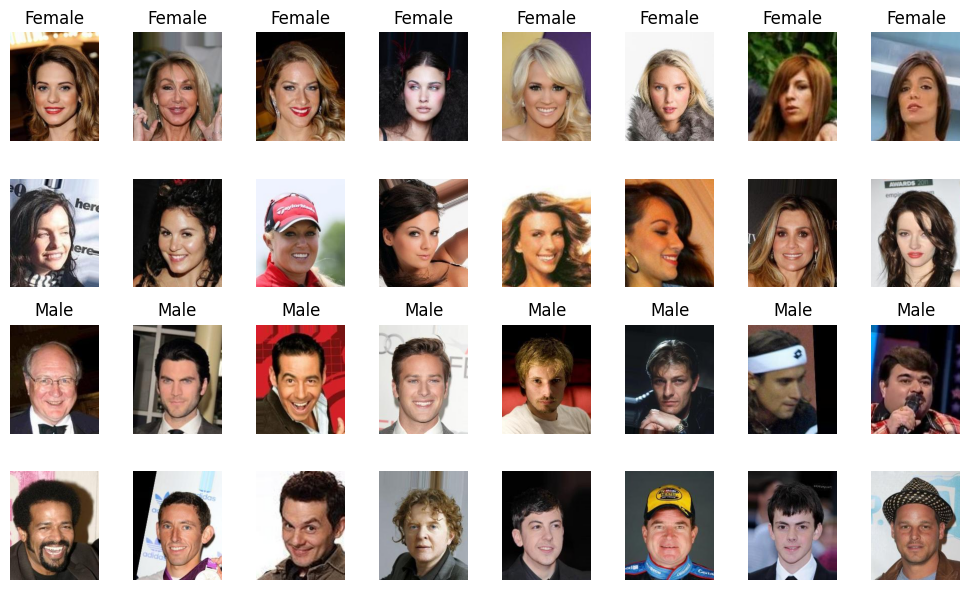

In [6]:
train_dataset = GenderDataset(os.path.join(DATA_DIR, "Train"))
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
visualize_batch(train_dataloader)

Train


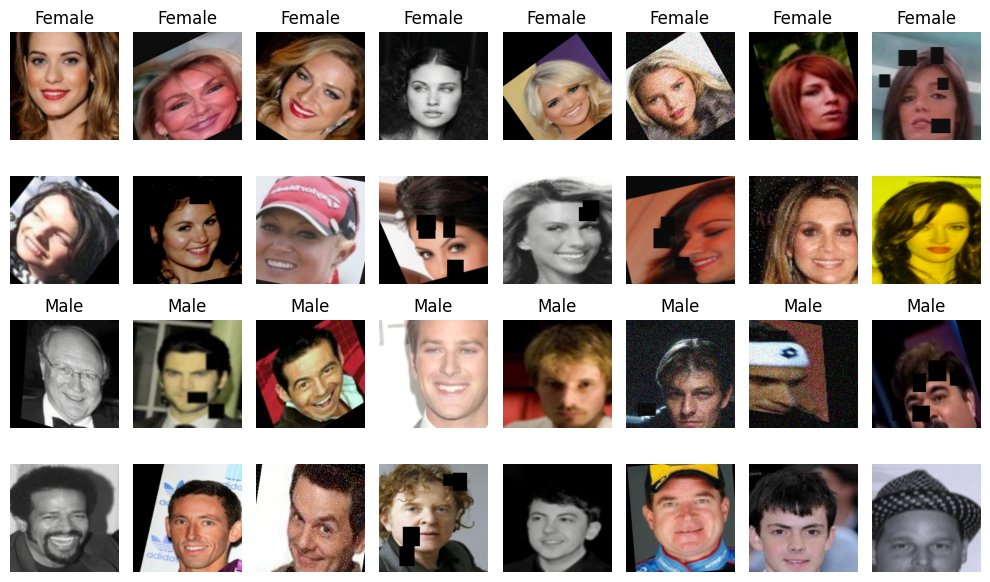

Val


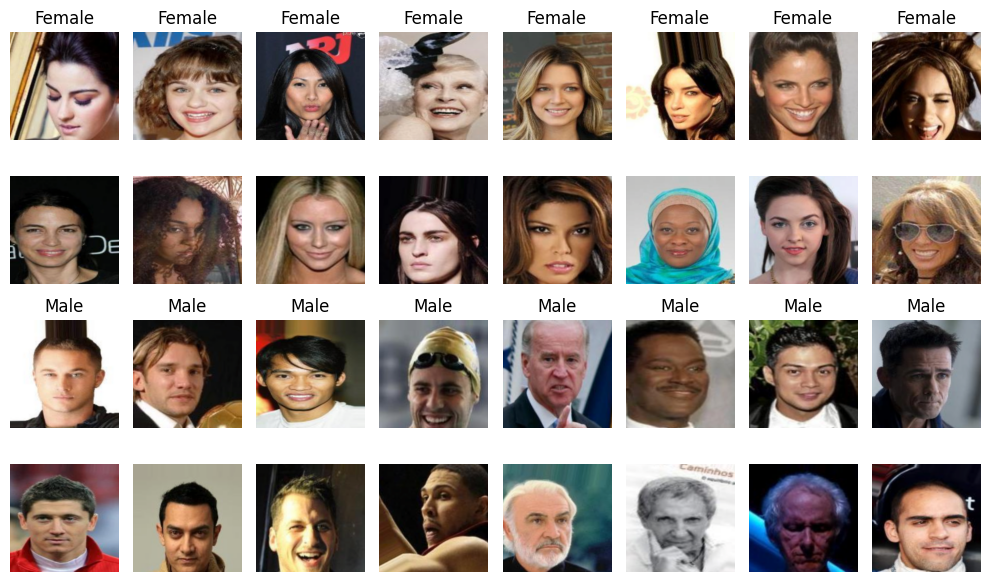

In [7]:
def get_transform():
    train_transform = A.Compose([
        A.Resize(256, 256),
        A.RandomResizedCrop(size=(224, 224), scale=(0.4, 1.0), p=1.0),
        A.HorizontalFlip(p=0.5),
        # Affine
        A.Affine(scale=(0.8, 1.2), rotate=(-40, 40),
                 translate_percent=(-0.1, 0.1), shear=(-10, 10), p=0.5),
        # Dropout / Occlusion
        A.CoarseDropout(num_holes_range=(1, 6), hole_height_range=(0.1, 0.2),
                        hole_width_range=(0.1, 0.2), p=0.3),
        # Color Space Reduction
        A.OneOf([
            A.ToGray(p=1.0),
            A.ChannelDropout(p=1.0),
        ], p=0.2),
        # Color Augmentations
        A.OneOf([
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.8),
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.8),
            A.HueSaturationValue(hue_shift_limit=20, sat_shift_limit=30, val_shift_limit=20, p=0.8),
            A.RandomGamma(gamma_limit=(80, 120), p=0.8),
        ], p=0.5),
        # Blur
        A.OneOf([
            A.GaussianBlur(blur_limit=(3, 7), p=0.5),
            A.MedianBlur(blur_limit=5, p=0.5),
            A.MotionBlur(blur_limit=(3, 7), p=0.5),
        ], p=0.2),
        # Noise
        A.OneOf([
            A.GaussNoise(std_range=(0.1, 0.2), p=0.5),
            A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=0.5),
            A.MultiplicativeNoise(multiplier=(0.9, 1.1), per_channel=True, p=0.5),
            A.SaltAndPepper(p=0.5)
        ], p=0.2),
        # Compression / Downscaling
        A.OneOf([
            A.ImageCompression(quality_range=(20, 80), p=0.5),
            A.Downscale(scale_range=(0.25, 0.5), p=0.5),
        ], p=0.2),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ])

    val_test_transform = A.Compose([
        A.Resize(height=256, width=256),
        # A.CenterCrop(height=224, width=224),
        A.RandomResizedCrop(size=(224, 224), scale=(0.6, 1.0), p=1.0),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ])
    return train_transform, val_test_transform

train_transform, val_test_transform = get_transform()

train_dataset = GenderDataset(os.path.join(DATA_DIR, "Train"), transform=train_transform)
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))

val_dataset = GenderDataset(os.path.join(DATA_DIR, "Val"), transform=val_test_transform)
val_dataloader = DataLoader(val_dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))

print("Train")
visualize_batch(train_dataloader, denormalize=True)
print("Val")
visualize_batch(val_dataloader, denormalize=True)

> Training

In [8]:
from typing import Literal

def get_model(model_type: Literal['resnet18', 'efficientnet_v2_s'], freeze_backbone=False):
    if model_type == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        if freeze_backbone:
            for param in model.parameters():
                param.requires_grad = False
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(0.2, inplace=True),
            nn.Linear(in_features, 2)
        )
    elif model_type == "efficientnet_v2_s":
        model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        if freeze_backbone:
            for param in model.parameters():
                param.requires_grad = False
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.2, inplace=True),
            nn.Linear(in_features, 2)
        )
    return model

In [9]:
def train(model, criterion, optimizer, scheduler, dataloaders, num_epochs, model_name):
    best_acc = 0.0
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': []
    }
    dataset_sizes = {x: len(dataloaders[x].dataset) for x in ['train', 'val']}
    
    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 20)
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()
            running_loss = 0.0
            running_corrects = 0
            pbar = tqdm(dataloaders[phase], desc=f'{phase}')
            for inputs, labels in pbar:
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                pbar.set_postfix({'loss': loss.item()})
            if phase == 'train' and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            
            print(f'{phase} loss: {epoch_loss:.4f} acc: {epoch_acc:.4f}')
            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.cpu().numpy())
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.cpu().numpy())
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                torch.save(model.state_dict(), f"{model_name}_best.pth")
                print(f"Saved best model: {best_acc:.4f}")

    torch.save(model.state_dict(), f"{model_name}_last.pth")
    print("Saved last model")
    return history

**resnet18**

In [10]:
model = get_model("resnet18", True)

_ = summary(model, input_size=(16, 3, 224, 224),  # (batch_size, channels, height, width)
    verbose=1,col_names=["input_size", "output_size", "num_params"])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ResNet                                   [16, 3, 224, 224]         [16, 2]                   --
├─Conv2d: 1-1                            [16, 3, 224, 224]         [16, 64, 112, 112]        (9,408)
├─BatchNorm2d: 1-2                       [16, 64, 112, 112]        [16, 64, 112, 112]        (128)
├─ReLU: 1-3                              [16, 64, 112, 112]        [16, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [16, 64, 112, 112]        [16, 64, 56, 56]          --
├─Sequential: 1-5                        [16, 64, 56, 56]          [16, 64, 56, 56]          --
│    └─BasicBlock: 2-1                   [16, 64, 56, 56]          [16, 64, 56, 56]          --
│    │    └─Conv2d: 3-1                  [16, 64, 56, 56]          [16, 64, 56, 56]          (36,864)
│    │    └─BatchNorm2d: 3-2             [16, 64, 56, 56]          [16, 64, 56, 56]          (128)
│    │    └─ReLU: 

In [11]:
train_transform, val_test_transform = get_transform()

train_dataset = GenderDataset(os.path.join(DATA_DIR, "Train"), transform=train_transform)
val_dataset = GenderDataset(os.path.join(DATA_DIR, "Val"), transform=val_test_transform)

dataloaders = {
    "train": DataLoader(train_dataset, batch_size=32, shuffle=True),
    "val": DataLoader(val_dataset, batch_size=32, shuffle=False)
}

print("TRANSFER LEARNING")
resnet18_model = get_model("resnet18", freeze_backbone=True)
resnet18_model = resnet18_model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet18_model.parameters(), lr=0.001)

train(resnet18_model, criterion, optimizer, None, dataloaders, 10, model_name="resnet18")


print("FINETUNING")
resnet18_model = get_model("resnet18", freeze_backbone=False)
resnet18_model.load_state_dict(torch.load("resnet18_last.pth"))
resnet18_model = resnet18_model.to(DEVICE)

optimizer = torch.optim.Adam(resnet18_model.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

history = train(resnet18_model, criterion, optimizer, scheduler, dataloaders, 40, model_name="resnet18")

TRANSFER LEARNING
Epoch 1/10
--------------------


train: 100%|██████████| 250/250 [00:56<00:00,  4.46it/s, loss=0.365]


train loss: 0.5142 acc: 0.7355


val: 100%|██████████| 32/32 [00:05<00:00,  5.71it/s, loss=0.268]


val loss: 0.2476 acc: 0.9120
Saved best model: 0.9120
Epoch 2/10
--------------------


train: 100%|██████████| 250/250 [00:39<00:00,  6.28it/s, loss=0.345]


... (191 outputs left out)

train: 100%|██████████| 250/250 [00:53<00:00,  4.68it/s, loss=0.0202]


train loss: 0.0288 acc: 0.9904


val: 100%|██████████| 32/32 [00:03<00:00, 10.39it/s, loss=0.133]


val loss: 0.0668 acc: 0.9830
Saved last model


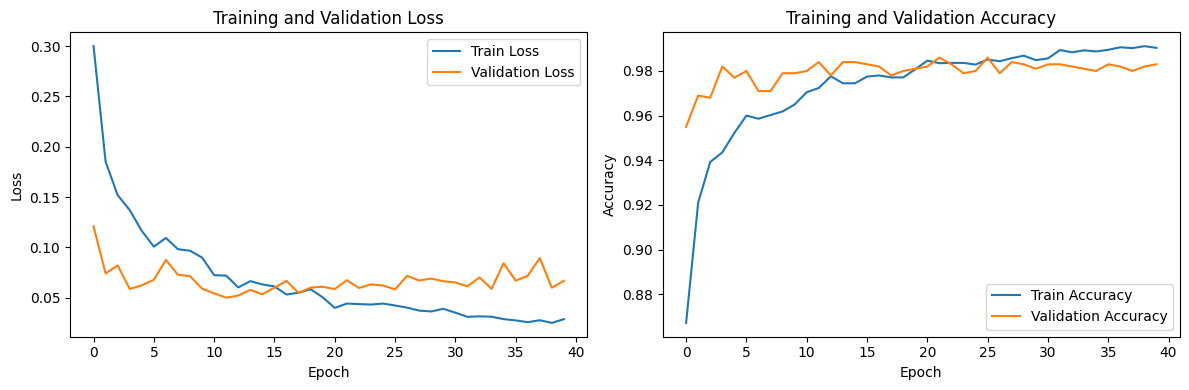

In [12]:
# loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

# accuracy
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.tight_layout()
plt.show()

**EfficientNet_V2_S**

In [13]:
model = get_model("efficientnet_v2_s", True)

_ = summary(model, input_size=(16, 3, 224, 224),  # (batch_size, channels, height, width)
    verbose=1,col_names=["input_size", "output_size", "num_params"])

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 206MB/s]


Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #
EfficientNet                                            [16, 3, 224, 224]         [16, 2]                   --
├─Sequential: 1-1                                       [16, 3, 224, 224]         [16, 1280, 7, 7]          --
│    └─Conv2dNormActivation: 2-1                        [16, 3, 224, 224]         [16, 24, 112, 112]        --
│    │    └─Conv2d: 3-1                                 [16, 3, 224, 224]         [16, 24, 112, 112]        (648)
│    │    └─BatchNorm2d: 3-2                            [16, 24, 112, 112]        [16, 24, 112, 112]        (48)
│    │    └─SiLU: 3-3                                   [16, 24, 112, 112]        [16, 24, 112, 112]        --
│    └─Sequential: 2-2                                  [16, 24, 112, 112]        [16, 24, 112, 112]        --
│    │    └─FusedMBConv: 3-4                            [16, 24, 112, 112]        [16, 24, 112, 112]  

In [14]:
train_transform, val_test_transform = get_transform()

train_dataset = GenderDataset(os.path.join(DATA_DIR, "Train"), transform=train_transform)
val_dataset = GenderDataset(os.path.join(DATA_DIR, "Val"), transform=val_test_transform)

dataloaders = {
    "train": DataLoader(train_dataset, batch_size=32, shuffle=True),
    "val": DataLoader(val_dataset, batch_size=32, shuffle=False)
}

print("TRANSFER LEARNING")
efficientnet_v2_s_model = get_model("efficientnet_v2_s", freeze_backbone=True)
efficientnet_v2_s_model = efficientnet_v2_s_model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(efficientnet_v2_s_model.parameters(), lr=0.001)

train(efficientnet_v2_s_model, criterion, optimizer, None, dataloaders, 10, model_name="efficientnet_v2_s")


print("FINETUNING")
efficientnet_v2_s_model = get_model("efficientnet_v2_s", freeze_backbone=False)
efficientnet_v2_s_model.load_state_dict(torch.load("efficientnet_v2_s_last.pth"))
efficientnet_v2_s_model = efficientnet_v2_s_model.to(DEVICE)

optimizer = torch.optim.Adam(efficientnet_v2_s_model.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

history = train(efficientnet_v2_s_model, criterion, optimizer, scheduler, dataloaders, 40, model_name="efficientnet_v2_s")

TRANSFER LEARNING
Epoch 1/10
--------------------


train: 100%|██████████| 250/250 [00:54<00:00,  4.63it/s, loss=0.354]


train loss: 0.4490 acc: 0.7925


val: 100%|██████████| 32/32 [00:05<00:00,  6.14it/s, loss=0.244]


val loss: 0.2765 acc: 0.8870
Saved best model: 0.8870
Epoch 2/10
--------------------


train: 100%|██████████| 250/250 [00:53<00:00,  4.67it/s, loss=0.343]


... (191 outputs left out)

train: 100%|██████████| 250/250 [02:00<00:00,  2.07it/s, loss=4.22e-6]


train loss: 0.0094 acc: 0.9965


val: 100%|██████████| 32/32 [00:05<00:00,  6.09it/s, loss=4.41e-5]


val loss: 0.0820 acc: 0.9840
Saved last model


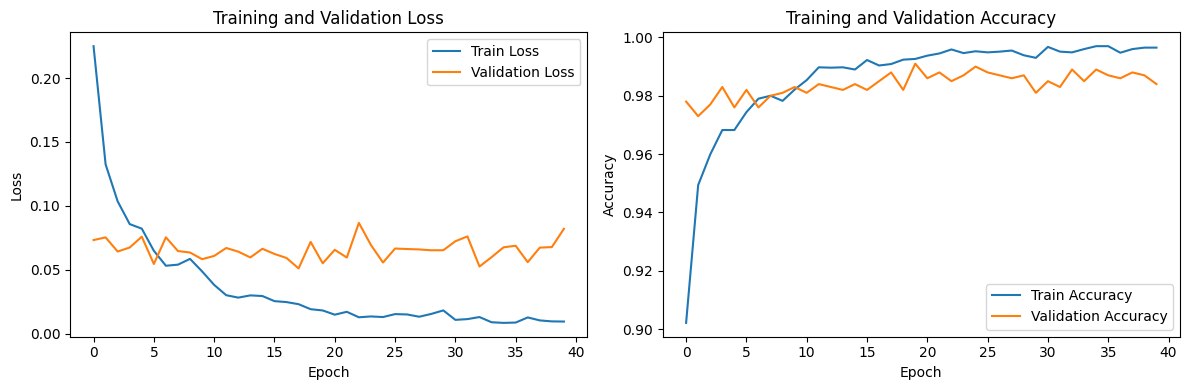

In [15]:
# loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

# accuracy
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.tight_layout()
plt.show()

**> Phân tích lỗi**

In [16]:
def analyze_misclassified_samples(model, val_dataloader, class_names):
    model = model.to(DEVICE)
    model.eval()
    misclassified_samples = []
    
    with torch.no_grad():
        for inputs, labels in val_dataloader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            incorrect_mask = preds != labels
            if incorrect_mask.any():
                incorrect_inputs = inputs[incorrect_mask]
                incorrect_labels = labels[incorrect_mask]
                incorrect_preds = preds[incorrect_mask]
                
                for i in range(len(incorrect_inputs)):
                    probs = torch.nn.functional.softmax(outputs[incorrect_mask][i], dim=0)
                    misclassified_samples.append({
                        'input': incorrect_inputs[i].cpu(),
                        'true_label': class_names[incorrect_labels[i].item()],
                        'pred_label': class_names[incorrect_preds[i].item()],
                        'confidence': probs[incorrect_preds[i]].item(),
                        'all_probs': probs.cpu().numpy()
                    })
    return misclassified_samples

def tensor_to_numpy_uint8(
    img_tensor, denormalize=True, 
    mean=[0.485, 0.456, 0.406], 
    std=[0.229, 0.224, 0.225],
    channel_first=True
):
    img = img_tensor.clone().detach()
    if img.is_cuda:
        img = img.cpu()
    img = img.numpy()
    if len(img.shape) == 4:
        img = img[0]
    if channel_first and len(img.shape) == 3:
        img = np.transpose(img, (1, 2, 0))
    if denormalize and len(img.shape) == 3 and img.shape[2] == 3:
        img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)
    img = (img * 255).astype(np.uint8)
    return img

def visualize(sample):
    for k, v in sample.items():
        if k != "input":
            print(f"{k}: {v}")
    img = tensor_to_numpy_uint8(sample["input"])
    plt.imshow(img)
    plt.show()

In [17]:
train_transform, val_test_transform = get_transform()
train_dataset = GenderDataset(os.path.join(DATA_DIR, "Train"), transform=train_transform)
val_dataset = GenderDataset(os.path.join(DATA_DIR, "Val"), transform=val_test_transform)

dataloaders = {
    "train": DataLoader(train_dataset, batch_size=32, shuffle=True),
    "val": DataLoader(val_dataset, batch_size=32, shuffle=False)
}

true_label: Female
pred_label: Male
confidence: 0.9923548698425293
all_probs: [0.00764513 0.99235487]


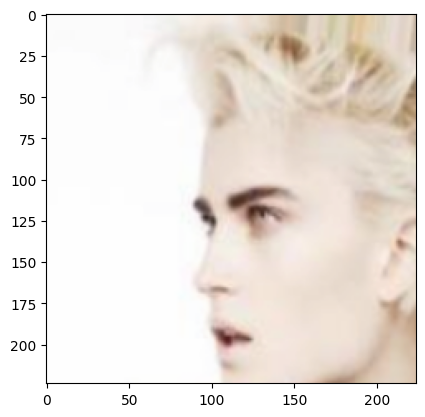

true_label: Female
pred_label: Male
confidence: 0.6111708879470825
all_probs: [0.38882914 0.6111709 ]


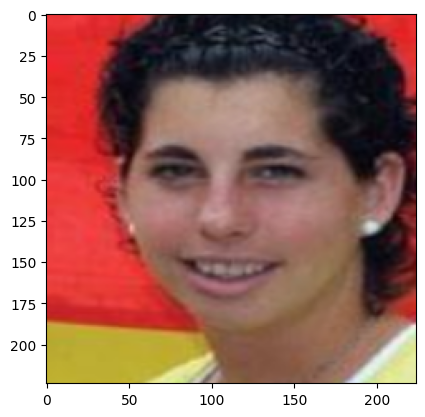

true_label: Female
pred_label: Male
confidence: 0.9955396056175232
all_probs: [0.00446039 0.9955396 ]


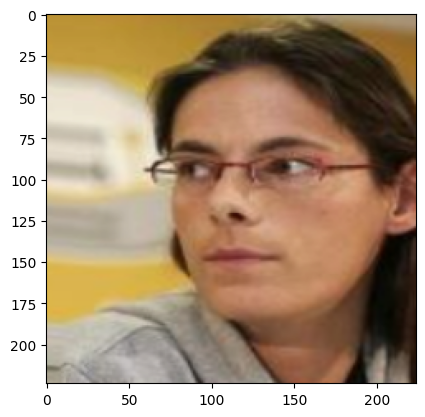

true_label: Female
pred_label: Male
confidence: 0.9951790571212769
all_probs: [0.00482096 0.99517906]


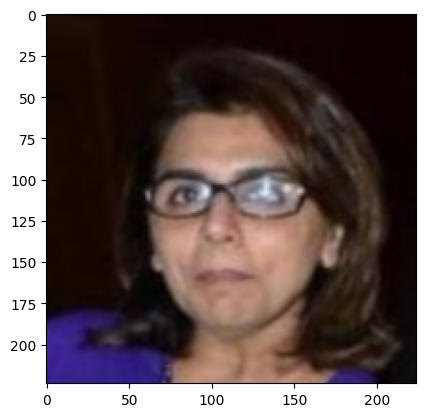

true_label: Female
pred_label: Male
confidence: 0.9000402092933655
all_probs: [0.09995978 0.9000402 ]


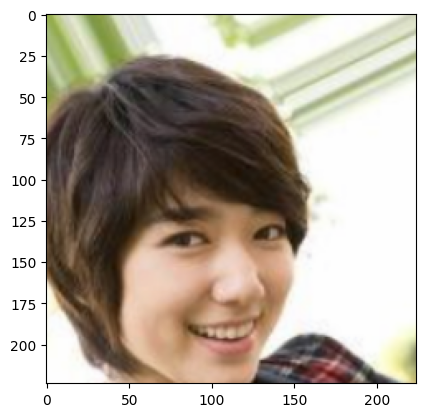

true_label: Female
pred_label: Male
confidence: 0.7944719791412354
all_probs: [0.20552804 0.794472  ]


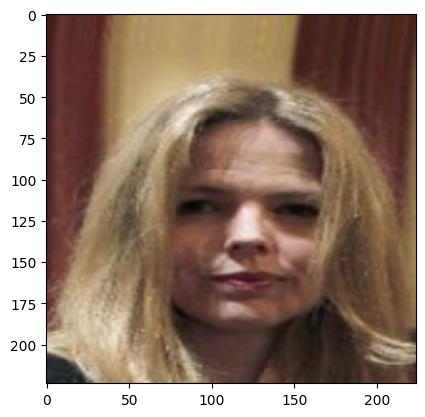

true_label: Female
pred_label: Male
confidence: 0.729067862033844
all_probs: [0.27093217 0.72906786]


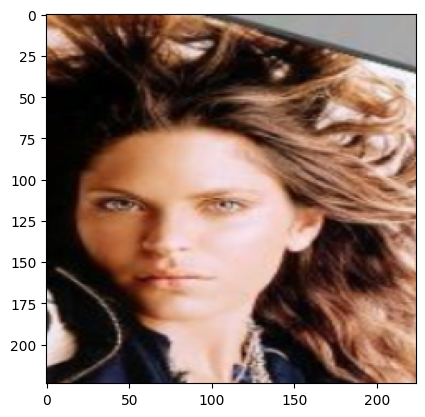

true_label: Female
pred_label: Male
confidence: 0.8727760314941406
all_probs: [0.12722395 0.87277603]


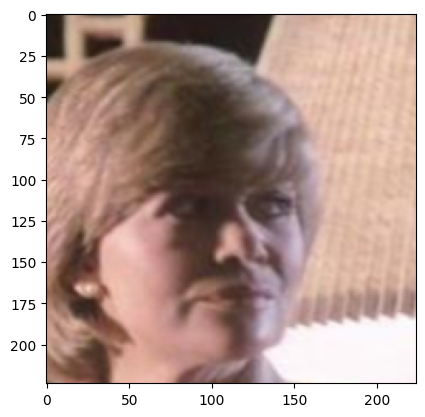

true_label: Female
pred_label: Male
confidence: 0.8230779767036438
all_probs: [0.17692204 0.823078  ]


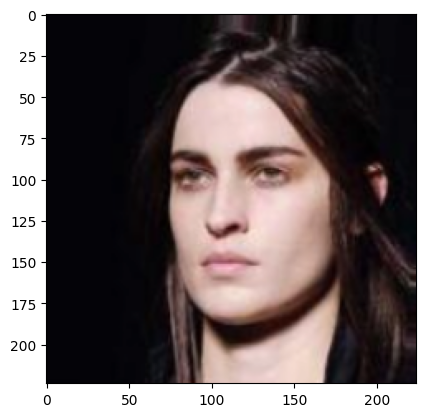

true_label: Female
pred_label: Male
confidence: 0.5352339744567871
all_probs: [0.46476603 0.535234  ]


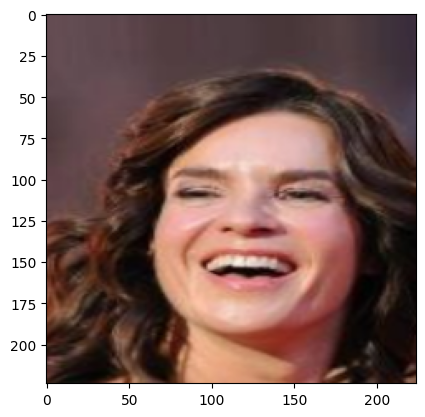

true_label: Female
pred_label: Male
confidence: 0.5365296602249146
all_probs: [0.4634703  0.53652966]


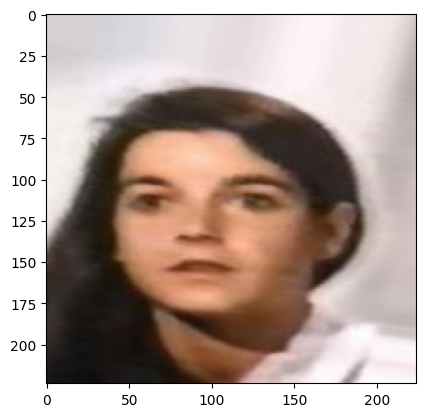

true_label: Female
pred_label: Male
confidence: 0.5790159106254578
all_probs: [0.4209841 0.5790159]


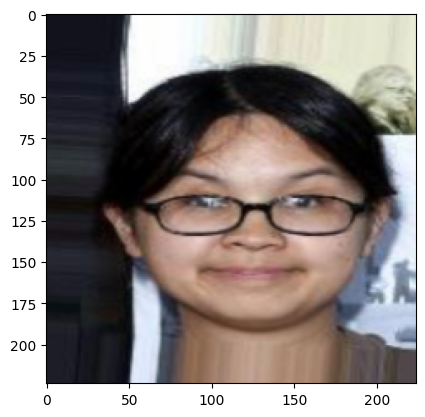

true_label: Female
pred_label: Male
confidence: 0.6574538946151733
all_probs: [0.34254608 0.6574539 ]


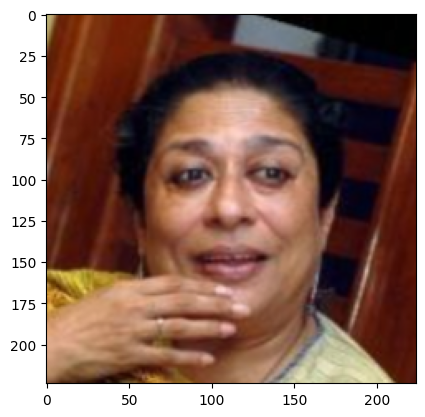

true_label: Female
pred_label: Male
confidence: 0.5282031297683716
all_probs: [0.47179687 0.5282031 ]


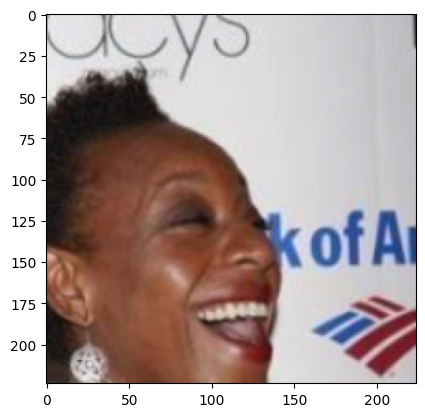

true_label: Female
pred_label: Male
confidence: 0.8117789030075073
all_probs: [0.18822117 0.8117789 ]


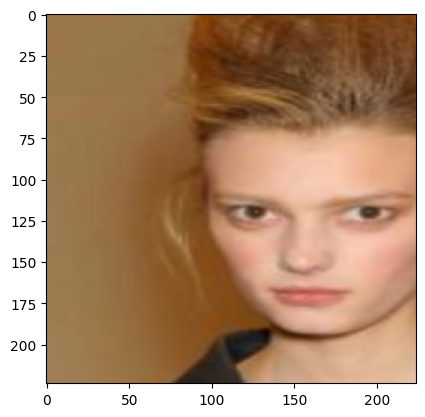

true_label: Female
pred_label: Male
confidence: 0.9969592094421387
all_probs: [0.00304082 0.9969592 ]


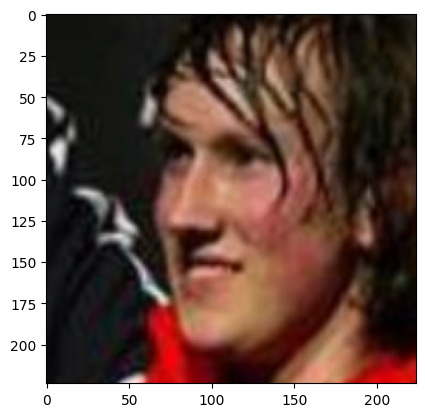

true_label: Male
pred_label: Female
confidence: 0.9729846715927124
all_probs: [0.9729847  0.02701529]


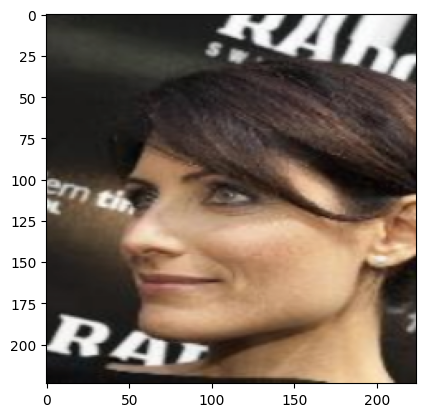

true_label: Male
pred_label: Female
confidence: 0.9349474906921387
all_probs: [0.9349475  0.06505244]


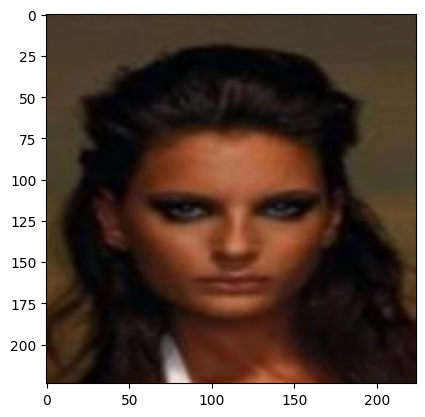

true_label: Male
pred_label: Female
confidence: 0.9915241003036499
all_probs: [0.9915241  0.00847594]


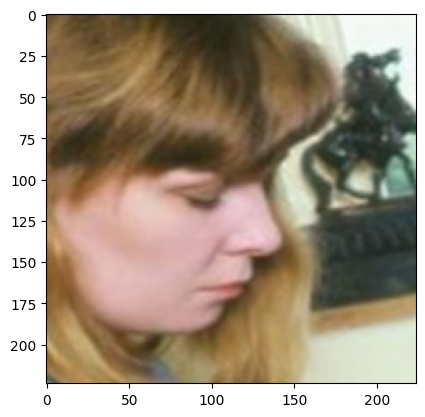

true_label: Male
pred_label: Female
confidence: 0.8774357438087463
all_probs: [0.87743574 0.1225642 ]


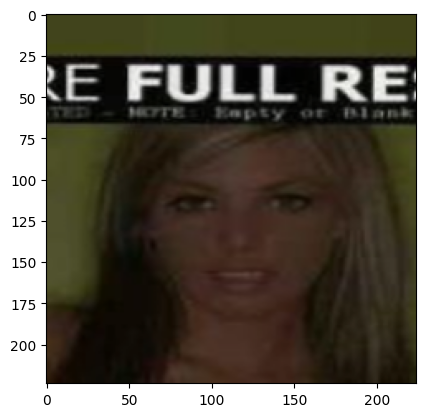

In [18]:
resnet18_model = get_model("resnet18", freeze_backbone=False)
resnet18_model.load_state_dict(torch.load("resnet18_best.pth", map_location=torch.device(DEVICE)))

misclassified_samples = analyze_misclassified_samples(resnet18_model, dataloaders["val"], ["Female", "Male"])

for sample in misclassified_samples:
    visualize(sample)

true_label: Female
pred_label: Male
confidence: 0.9941410422325134
all_probs: [0.00585893 0.99414104]


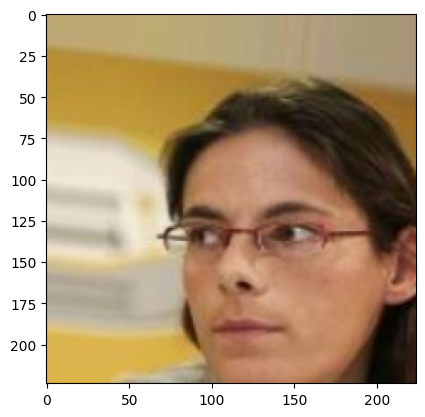

true_label: Female
pred_label: Male
confidence: 0.9972522854804993
all_probs: [0.0027477 0.9972523]


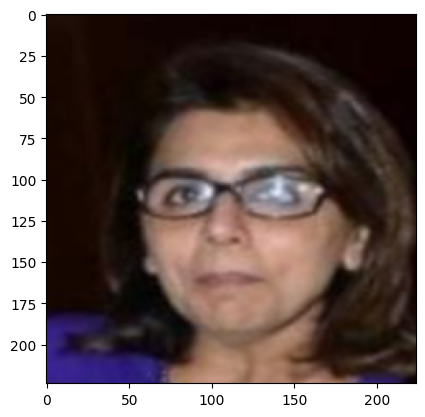

true_label: Female
pred_label: Male
confidence: 0.9972336888313293
all_probs: [0.00276634 0.9972337 ]


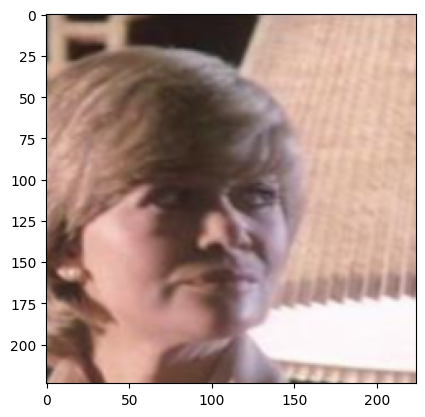

true_label: Female
pred_label: Male
confidence: 0.9281287789344788
all_probs: [0.07187116 0.9281288 ]


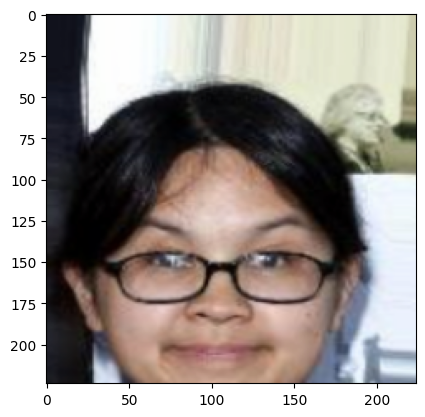

true_label: Female
pred_label: Male
confidence: 0.9998849630355835
all_probs: [1.1498401e-04 9.9988496e-01]


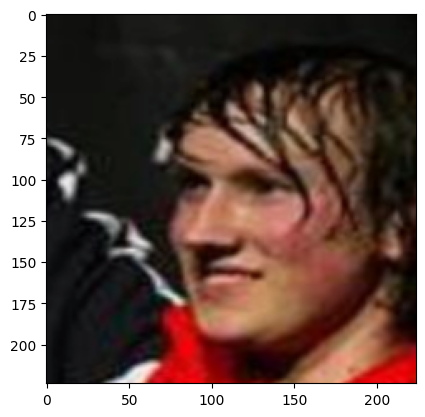

true_label: Male
pred_label: Female
confidence: 0.9447832107543945
all_probs: [0.9447832  0.05521679]


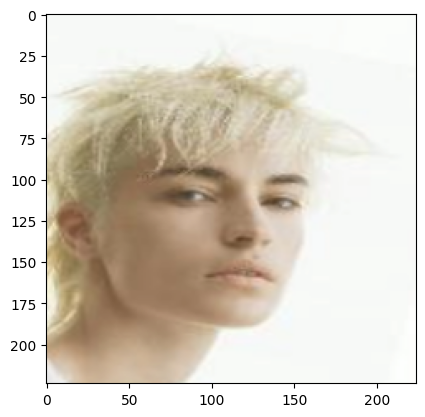

true_label: Male
pred_label: Female
confidence: 0.9997327923774719
all_probs: [9.9973279e-01 2.6716906e-04]


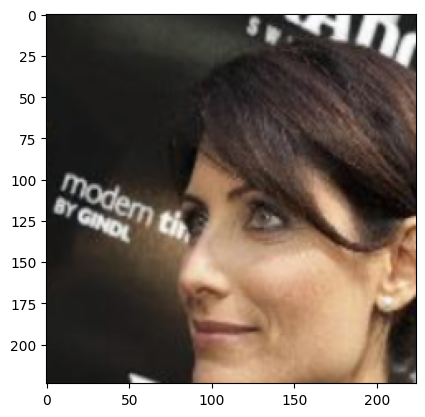

true_label: Male
pred_label: Female
confidence: 0.9821646213531494
all_probs: [0.9821646  0.01783539]


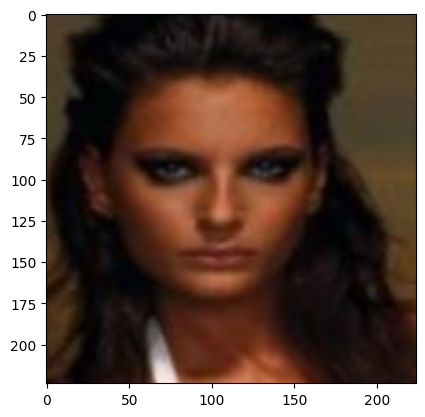

true_label: Male
pred_label: Female
confidence: 0.9998214840888977
all_probs: [9.9982148e-01 1.7858656e-04]


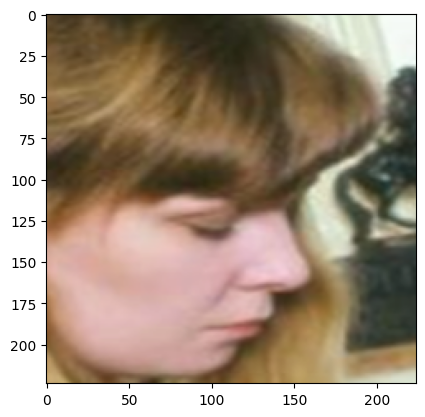

true_label: Male
pred_label: Female
confidence: 0.9999006986618042
all_probs: [9.9990070e-01 9.9299024e-05]


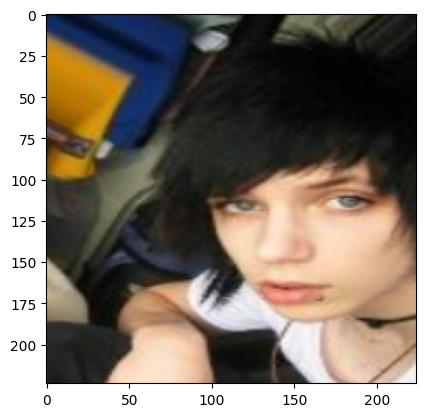

In [19]:
efficientnet_v2_s_model = get_model("efficientnet_v2_s", freeze_backbone=False)
efficientnet_v2_s_model.load_state_dict(torch.load("efficientnet_v2_s_best.pth", torch.device(DEVICE)))
misclassified_samples = analyze_misclassified_samples(efficientnet_v2_s_model, dataloaders["val"], train_dataset.classes)

for sample in misclassified_samples:
    visualize(sample)

In [20]:
def get_tta_transform():
    return [
        A.Compose([
            A.Resize(height=256, width=256),
            A.CenterCrop(height=224, width=224),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2(),
        ]),
        A.Compose([
            A.Resize(height=256, width=256),
            A.CenterCrop(height=100, width=100),
            A.Resize(height=224, width=224),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2(),
        ]),
        A.Compose([
            A.Resize(height=256, width=256),
            A.CenterCrop(height=120, width=120),
            A.Resize(height=224, width=224),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2(),
        ]),
        A.Compose([
            A.Resize(height=256, width=256),
            A.CenterCrop(height=150, width=150),
            A.Resize(height=224, width=224),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2(),
        ]),
        A.Compose([
            A.Resize(height=256, width=256),
            A.CenterCrop(height=160, width=160),
            A.Resize(height=224, width=224),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2(),
        ]),
    ]

In [21]:
class TTAGenderDataset(Dataset):
    def __init__(self, folder_path, transforms_list):
        self.folder_path = folder_path
        self.transforms_list = transforms_list
        self.image_paths = []
        self.image_names = []

        filenames = []
        for filename in os.listdir(folder_path):
            if filename.lower().endswith('.jpg'):
                filenames.append(filename)
        filenames.sort()
        for filename in filenames:
            self.image_paths.append(os.path.join(folder_path, filename))
            self.image_names.append(filename.split(".")[0])
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image_name = self.image_names[idx]
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        augmented_images = []
        for transform in self.transforms_list:
            augmented = transform(image=image)
            augmented_images.append(augmented['image'])
        
        return {
            'images': augmented_images,
            'path': image_path,
            'name': image_name
        }

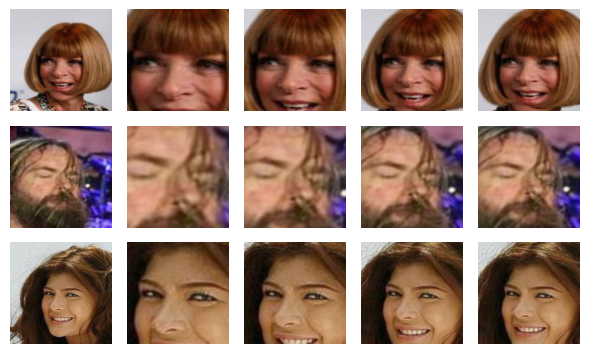

In [22]:
def visualize_tta(dataset, num_samples=3):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    def denormalize(tensor):
        img = tensor.cpu().numpy().transpose(1, 2, 0)
        img = img * std + mean  # Denormalize
        img = np.clip(img, 0, 1)
        return img
    tta_transforms = get_tta_transform()
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)
    num_transforms = len(tta_transforms)
    fig, axes = plt.subplots(num_samples, num_transforms, figsize=(6, 4))
    for i, idx in enumerate(indices):
        sample = dataset[idx]
        for j, tensor_img in enumerate(sample['images']):
            denorm_img = denormalize(tensor_img)
            axes[i, j].imshow(denorm_img)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()


visualize_tta(TTAGenderDataset(os.path.join(DATA_DIR, "Test"), get_tta_transform()))

In [23]:
def load_ensemble_models():
    models_list = []

    resnet18_best = get_model("resnet18", freeze_backbone=False)
    resnet18_best.load_state_dict(torch.load("resnet18_best.pth", map_location=torch.device(DEVICE)))
    resnet18_best = resnet18_best.to(DEVICE)
    resnet18_best.eval()
    models_list.append(resnet18_best)

    resnet18_last = get_model("resnet18", freeze_backbone=False)
    resnet18_last.load_state_dict(torch.load("resnet18_last.pth", map_location=torch.device(DEVICE)))
    resnet18_last = resnet18_last.to(DEVICE)
    resnet18_last.eval()
    models_list.append(resnet18_last)

    efficientnet_v2_s_best = get_model("efficientnet_v2_s", freeze_backbone=False)
    efficientnet_v2_s_best.load_state_dict(torch.load("efficientnet_v2_s_best.pth", map_location=torch.device(DEVICE)))
    efficientnet_v2_s_best = efficientnet_v2_s_best.to(DEVICE)
    efficientnet_v2_s_best.eval()
    models_list.append(efficientnet_v2_s_best)

    efficientnet_v2_s_last = get_model("efficientnet_v2_s", freeze_backbone=False)
    efficientnet_v2_s_last.load_state_dict(torch.load("efficientnet_v2_s_last.pth", map_location=torch.device(DEVICE)))
    efficientnet_v2_s_last = efficientnet_v2_s_last.to(DEVICE)
    efficientnet_v2_s_last.eval()
    models_list.append(efficientnet_v2_s_last)

    return models_list

In [24]:
def predict_with_ensemble_tta(models_list, dataloader):
    results = []
    softmax = nn.Softmax(dim=1)
    num_models = len(models_list)
    equal_weight = 1.0 / num_models
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Predicting with Ensemble TTA"):
            images_list = batch['images']  
            names = batch['name']
            
            num_augments = len(images_list)
            
            batch_size = len(names)
            final_probs = torch.zeros((batch_size, 2)).to(DEVICE)
            
            for model_idx, model in enumerate(models_list):
                
                model_probs = torch.zeros((batch_size, 2)).to(DEVICE)
                
                for aug_idx in range(num_augments):
                    aug_images = images_list[aug_idx].to(DEVICE)
                    outputs = model(aug_images)
                    probs = softmax(outputs)

                    model_probs += probs
                model_avg_probs = model_probs / num_augments

                final_probs += model_avg_probs * equal_weight

            final_preds = torch.argmax(final_probs, dim=1)
            
            for i in range(len(names)):
                file_name = names[i]
                prediction = abs(1 - final_preds[i].item())
                confidence = final_probs[i][1 - prediction].item()
                
                results.append({
                    'ID': file_name,
                    'Label': prediction,
                    'Confidence': confidence
                })
    
    return results

In [25]:
import csv

test_dataset = TTAGenderDataset(os.path.join(DATA_DIR, "Test"), get_tta_transform())
test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)
models_list = load_ensemble_models()
results = predict_with_ensemble_tta(models_list, test_dataloader)

with open("ensemble_tta_submission.csv", 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['ID', 'Label'])
        writer.writeheader()
        for result in results:
            writer.writerow({
                'ID': result['ID'], 
                'Label': result['Label']
            })

Predicting with Ensemble TTA: 100%|██████████| 63/63 [00:52<00:00,  1.20it/s]
